In [ ]:
import pandas as pd                 ##hämta o läsa in datasetet
import numpy as np                  ##arbeta med numreiska värden
import matplotlib.pyplot as plt     ##skapa diagram

Nedan hämtas dataset

In [ ]:
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "wine-quality/winequality-red.csv"
)

df = pd.read_csv(url, sep=";") 

df.head()       ##visar de första 5 raderna i datasetet så man vet att de importerats

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
print("Antal rader och kolumner", df.shape)
print("\nKolumner:")
print(df.columns)

print("Saknade värden:")
print(df.isnull().sum())
## Jag kontrollerar saknade värden eftersom de kan göra att modellen inte kan tränas korrekt

Antal rader och kolumner (1599, 12)

Kolumner:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')
Saknade värden:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


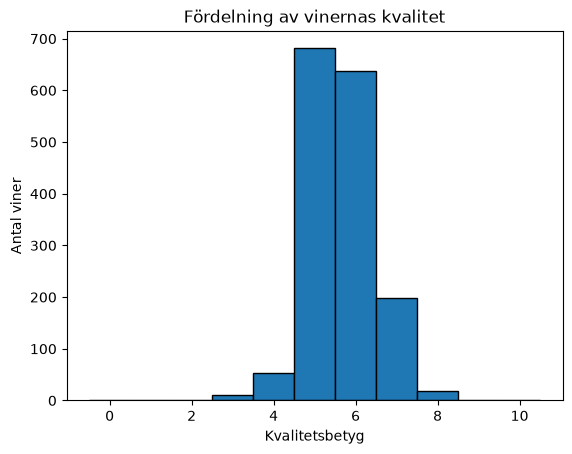

In [ ]:
plt.hist(df["quality"], ##räknar hur många viner som har olika kvalitetsbetyg
bins=range(0, 12), ##skapar intervall från 0 till 11
align="left", ##placerar staplarna så de börjar vid heltalsvärdet
edgecolor="black") ##gör kanterna tydligare/snyggare

plt.xlabel("Kvalitetsbetyg")
plt.ylabel("Antal viner")
plt.title("Fördelning av vinernas kvalitet")
plt.show()

## 2. Uppdelning av data

Jag delar upp datan i träningsdata, valideringsdata
och testdata.

Träningsdatan används för att träna modellerna.
Valideringsdatan används för att jämföra modellerna.
Testdatan används för att kontrollera hur bra den
valda modellen fungerar på ny data.

In [ ]:
# Importerar funktionen som används för att dela upp data
from sklearn.model_selection import train_test_split

# X innehåller alla kemiska värden som modellen ska använda men
# Vi tar bort quality eftersom det är det vi vill förutsäga
X = df.drop(columns=["quality"])

# y innehåller det riktiga kvalitetsbetyget för varje vin
y = df["quality"]

# Här är Första uppdelningen:
# 80 % av datan sparas till träning och validering
# 20 % läggs undan som testdata
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) 
##random_state bestämmer hur datan blandas innan den delas upp, vilket gör resultatet reproducerbart

# Andra uppdelningen:
# Vi delar de resterande 80 procenten i träning och validering
# 25 % av dessa 80 % blir 20 % av hela datasetet
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42
)

# Skriver ut hur många viner som finns i varje grupp
print("Träning:", len(X_train))
print("Validering:", len(X_val))
print("Test:", len(X_test))

Träning: 959
Validering: 320
Test: 320


## 3. Baseline

Jag använder en enkel baseline-modell för att ha
något att jämföra mina andra modeller med.

För regression använder jag DummyRegressor som
alltid förutsäger medelvärdet från träningsdatan.

In [6]:
# Importerar vår baseline-modell för regression
from sklearn.dummy import DummyRegressor

# Importerar funktioner för att mäta modellens fel
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Skapar en modell som alltid gissar medelvärdet
baseline_reg = DummyRegressor(strategy="mean")

# Tränar modellen på träningsdatan
baseline_reg.fit(X_train, y_train)

# Låter modellen förutsäga kvaliteten på valideringsdatan
y_pred = baseline_reg.predict(X_val)

# Räknar ut hur stora fel modellen gör
rmse = root_mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

# Skriver ut resultaten
print("Baseline RMSE:", round(rmse, 3))
print("Baseline MAE:", round(mae, 3))
print("Baseline R2:", round(r2, 3))

Baseline RMSE: 0.802
Baseline MAE: 0.686
Baseline R2: -0.014


In [7]:
# Importerar baseline-modellen för klassificering
from sklearn.dummy import DummyClassifier

# Importerar måttet accuracy
from sklearn.metrics import accuracy_score

# Skapar målvariabler för klassificering
# Betyg 7 eller högre = 1 (bra vin)
# Betyg under 7 = 0 (inte bra vin)
y_train_clf = (y_train >= 7).astype(int)
y_val_clf = (y_val >= 7).astype(int)

# Skapar en modell som alltid väljer den vanligaste klassen
baseline_clf = DummyClassifier(strategy="most_frequent")

# Tränar modellen
baseline_clf.fit(X_train, y_train_clf)

# Gör förutsägelser på valideringsdatan
y_pred_clf = baseline_clf.predict(X_val)

# Beräknar accuracy
accuracy = accuracy_score(y_val_clf, y_pred_clf)

# Skriver ut resultatet
print("Baseline accuracy:", round(accuracy, 3))

Baseline accuracy: 0.884


In [22]:
# Importerar utvärderingsmåtten
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Beräknar precision, recall och F1 för baseline
baseline_precision = precision_score(y_val_clf, y_pred_clf, zero_division=0)
baseline_recall = recall_score(y_val_clf, y_pred_clf)
baseline_f1 = f1_score(y_val_clf, y_pred_clf)

# Hämtar sannolikheten för att ett vin är bra
baseline_proba = baseline_clf.predict_proba(X_val)[:, 1]

# Beräknar AUC
baseline_auc = roc_auc_score(y_val_clf, baseline_proba)

# Skriver ut resultaten
print("Accuracy:", round(accuracy, 3))
print("Precision:", round(baseline_precision, 3))
print("Recall:", round(baseline_recall, 3))
print("F1:", round(baseline_f1, 3))
print("AUC:", round(baseline_auc, 3))

Accuracy: 0.884
Precision: 0.0
Recall: 0.0
F1: 0.0
AUC: 0.5


## 4. Regression

Jag ska jämföra LinearRegression, Ridge och
RandomForestRegressor för att se vilken modell
som bäst kan förutsäga vinernas kvalitetsbetyg.

In [15]:
# Importerar linjär regression
from sklearn.linear_model import LinearRegression

# Importerar skalning och Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Skapar modellen med skalning
# StandardScaler gör att variablerna får jämförbara skalor
linear_model = make_pipeline(StandardScaler(), LinearRegression())

# Tränar modellen på träningsdatan
linear_model.fit(X_train, y_train)

# Förutsäger kvalitetsbetyg på valideringsdatan
linear_pred = linear_model.predict(X_val)

# Beräknar RMSE, MAE och R2
linear_rmse = root_mean_squared_error(y_val, linear_pred)
linear_mae = mean_absolute_error(y_val, linear_pred)
linear_r2 = r2_score(y_val, linear_pred)

# Skriver ut resultaten
print("LinearRegression RMSE:", round(linear_rmse, 3))
print("LinearRegression MAE:", round(linear_mae, 3))
print("LinearRegression R2:", round(linear_r2, 3))

LinearRegression RMSE: 0.674
LinearRegression MAE: 0.5
LinearRegression R2: 0.284


### Ridge Regression

Ridge liknar LinearRegression men använder
regularisering för att minska risken för överanpassning.

Jag testar tre olika alpha-värden för att se hur
de påverkar modellens resultat.

In [30]:
# Importerar Ridge
from sklearn.linear_model import Ridge

# Testar tre olika alpha-värden
for alpha in [0.1, 1, 10]:

# Skapar Ridge-modellen med skalning
    ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))

    # Tränar modellen på träningsdatan
    ridge_model.fit(X_train, y_train)

    # Gör förutsägelser på valideringsdatan
    ridge_pred = ridge_model.predict(X_val)

    # Beräknar RMSE, MAE och R2
    ridge_rmse = root_mean_squared_error(y_val, ridge_pred)
    ridge_mae = mean_absolute_error(y_val, ridge_pred)
    ridge_r2 = r2_score(y_val, ridge_pred)

    # Skriver ut resultaten för varje alpha-värde
    print("Alpha:", alpha)
    print("RMSE:", round(ridge_rmse, 3))
    print("MAE:", round(ridge_mae, 3))
    print("R2:", round(ridge_r2, 3))
    print()

Alpha: 0.1
RMSE: 0.674
MAE: 0.5
R2: 0.284

Alpha: 1
RMSE: 0.674
MAE: 0.5
R2: 0.284

Alpha: 10
RMSE: 0.674
MAE: 0.501
R2: 0.285



### RandomForestRegressor

Random Forest använder flera beslutsträd för att
förutsäga vinernas kvalitet.

Jag testar olika värden på max_depth för att se
hur trädens djup påverkar resultaten.

In [ ]:
# Importerar Random Forest för regression
from sklearn.ensemble import RandomForestRegressor

# Testar tre olika värden på max_depth
for depth in [3, 5, 10]:

    # Skapar modellen med valt djup
    rf_model = RandomForestRegressor(
        max_depth=depth,
        random_state=42
    )

    # Tränar modellen
    rf_model.fit(X_train, y_train)

    # Gör förutsägelser på valideringsdatan
    rf_pred = rf_model.predict(X_val)

    # Gör även förutsägelser på träningsdatan
    rf_train_pred = rf_model.predict(X_train)

    # Beräknar resultaten på valideringsdatan
    rf_rmse = root_mean_squared_error(y_val, rf_pred)
    rf_mae = mean_absolute_error(y_val, rf_pred)
    rf_r2 = r2_score(y_val, rf_pred)

    # Beräknar RMSE på träningsdatan
    rf_train_rmse = root_mean_squared_error(y_train, rf_train_pred)

    # Skriver ut resultaten
    print("Max depth:", depth)
    print("Träning RMSE:", round(rf_train_rmse, 3))
    print("Validering RMSE:", round(rf_rmse, 3))
    print("MAE:", round(rf_mae, 3))
    print("R2:", round(rf_r2, 3))
    print()

Max depth: 3
Träning RMSE: 0.614
Validering RMSE: 0.67
MAE: 0.521
R2: 0.293

Max depth: 5
Träning RMSE: 0.529
Validering RMSE: 0.653
MAE: 0.493
R2: 0.327

Max depth: 10
Träning RMSE: 0.326
Validering RMSE: 0.621
MAE: 0.448
R2: 0.392



### Val av regressionsmodell

Jag valde RandomForestRegressor med max_depth=10
eftersom den fick lägst RMSE på valideringsdatan (0.621).

När jag ökade max_depth minskade både träningsfelet
och valideringsfelet. Skillnaden mellan dem blev
däremot större, vilket tyder på överanpassning.

Trots det fick modellen bäst resultat på
valideringsdatan av de modeller jag testade.

### Jämförelse av regressionsmodeller

Jag jämför modellernas resultat på valideringsdatan
för att se vilken modell som förutsäger vinernas
kvalitet bäst.

In [23]:
# Skapar en tabell med resultaten från våra regressionsmodeller
reg_results = pd.DataFrame({
    "Modell": [
        "DummyRegressor",
        "LinearRegression",
        "Ridge 0.1",
        "Ridge 1",
        "Ridge 10",
        "RandomForest 3",
        "RandomForest 5",
        "RandomForest 10"
    ],
    "RMSE": [0.802, 0.674, 0.674, 0.674, 0.674, 0.670, 0.653, 0.621],
    "MAE": [0.686, 0.500, 0.500, 0.500, 0.501, 0.521, 0.493, 0.448],
    "R2": [-0.014, 0.284, 0.284, 0.284, 0.285, 0.293, 0.327, 0.392]
})

# Visar tabellen
reg_results

,Modell,RMSE,MAE,R2
0,DummyRegressor,0.802,0.686,-0.014
1,LinearRegression,0.674,0.500,0.284
2,Ridge 0.1,0.674,0.500,0.284
3,Ridge 1,0.674,0.500,0.284
4,Ridge 10,0.674,0.501,0.285
5,RandomForest 3,0.670,0.521,0.293
6,RandomForest 5,0.653,0.493,0.327
7,RandomForest 10,0.621,0.448,0.392


## 5. Klassificering

Nu ska jag förutsäga om ett vin är bra eller inte.

Viner med kvalitetsbetyg 7 eller högre räknas som
bra (1), medan övriga räknas som inte bra (0).

In [17]:
# Importerar logistisk regression
from sklearn.linear_model import LogisticRegression

# Skapar modellen med skalning
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Tränar modellen på klassificeringsdatan
log_model.fit(X_train, y_train_clf)

# Förutsäger om vinerna är bra eller inte
log_pred = log_model.predict(X_val)

# Beräknar accuracy
log_accuracy = accuracy_score(y_val_clf, log_pred)

# Skriver ut resultatet
print("LogisticRegression accuracy:", round(log_accuracy, 3))

LogisticRegression accuracy: 0.887


In [18]:
# Importerar fler utvärderingsmått för klassificering
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Beräknar precision, recall och F1
log_precision = precision_score(y_val_clf, log_pred, zero_division=0)
log_recall = recall_score(y_val_clf, log_pred)
log_f1 = f1_score(y_val_clf, log_pred)

# Hämtar sannolikheten för att ett vin är bra (klass 1)
log_proba = log_model.predict_proba(X_val)[:, 1]

# Beräknar AUC utifrån sannolikheterna
log_auc = roc_auc_score(y_val_clf, log_proba)

# Skriver ut resultaten
print("Accuracy:", round(log_accuracy, 3))
print("Precision:", round(log_precision, 3))
print("Recall:", round(log_recall, 3))
print("F1:", round(log_f1, 3))
print("AUC:", round(log_auc, 3))

Accuracy: 0.887
Precision: 0.522
Recall: 0.324
F1: 0.4
AUC: 0.851


### RandomForestClassifier

Jag testar Random Forest för att klassificera viner
som bra eller inte bra.

Jag jämför två olika max_depth för att se hur
trädens djup påverkar modellens resultat.

In [19]:
# Importerar Random Forest för klassificering
from sklearn.ensemble import RandomForestClassifier

# Testar två olika djup på beslutsträden
for depth in [5, 10]:

    # Skapar modellen
    rf_clf = RandomForestClassifier(
        max_depth=depth,
        random_state=42
    )

    # Tränar modellen
    rf_clf.fit(X_train, y_train_clf)

    # Förutsäger om vinerna är bra eller inte
    rf_clf_pred = rf_clf.predict(X_val)

    # Hämtar sannolikheten för klass 1 (bra vin)
    rf_clf_proba = rf_clf.predict_proba(X_val)[:, 1]

    # Beräknar utvärderingsmåtten
    rf_accuracy = accuracy_score(y_val_clf, rf_clf_pred)
    rf_precision = precision_score(y_val_clf, rf_clf_pred, zero_division=0)
    rf_recall = recall_score(y_val_clf, rf_clf_pred)
    rf_f1 = f1_score(y_val_clf, rf_clf_pred)
    rf_auc = roc_auc_score(y_val_clf, rf_clf_proba)

    # Skriver ut resultaten
    print("Max depth:", depth)
    print("Accuracy:", round(rf_accuracy, 3))
    print("Precision:", round(rf_precision, 3))
    print("Recall:", round(rf_recall, 3))
    print("F1:", round(rf_f1, 3))
    print("AUC:", round(rf_auc, 3))
    print()

Max depth: 5
Accuracy: 0.9
Precision: 0.727
Recall: 0.216
F1: 0.333
AUC: 0.848

Max depth: 10
Accuracy: 0.919
Precision: 0.72
Recall: 0.486
F1: 0.581
AUC: 0.882



### ROC-kurvor

Jag jämför modellernas ROC-kurvor för att se hur
bra de skiljer mellan bra och inte bra viner
vid olika tröskelvärden.

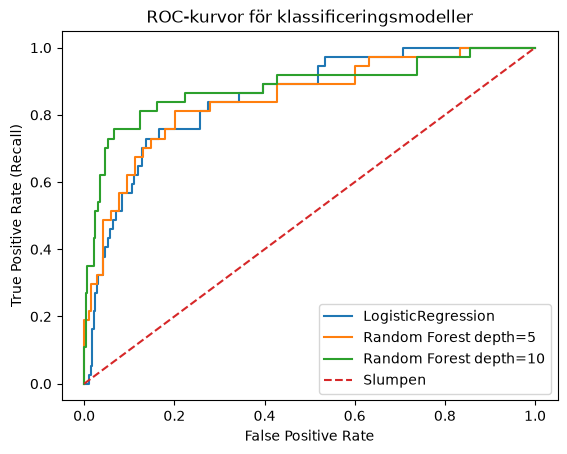

In [20]:
# Importerar funktionen för att skapa ROC-kurvor
from sklearn.metrics import roc_curve

# Tränar Random Forest med max_depth=5
rf5 = RandomForestClassifier(max_depth=5, random_state=42)
rf5.fit(X_train, y_train_clf)

# Tränar Random Forest med max_depth=10
rf10 = RandomForestClassifier(max_depth=10, random_state=42)
rf10.fit(X_train, y_train_clf)

# Hämtar sannolikheter för klass 1 (bra vin)
proba_rf5 = rf5.predict_proba(X_val)[:, 1]
proba_rf10 = rf10.predict_proba(X_val)[:, 1]

# Beräknar ROC-kurvor för våra tre modeller
fpr_log, tpr_log, _ = roc_curve(y_val_clf, log_proba)
fpr_rf5, tpr_rf5, _ = roc_curve(y_val_clf, proba_rf5)
fpr_rf10, tpr_rf10, _ = roc_curve(y_val_clf, proba_rf10)

# Ritar ROC-kurvorna
plt.plot(fpr_log, tpr_log, label="LogisticRegression")
plt.plot(fpr_rf5, tpr_rf5, label="Random Forest depth=5")
plt.plot(fpr_rf10, tpr_rf10, label="Random Forest depth=10")

# Ritar diagonalen som motsvarar slumpen
plt.plot([0, 1], [0, 1], "--", label="Slumpen")

# Namnger diagrammet och axlarna
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-kurvor för klassificeringsmodeller")
plt.legend()
plt.show()

### Jämförelse av klassificeringsmodeller

Jag jämför modellernas resultat på valideringsdatan
med accuracy, precision, recall, F1 och AUC.

In [24]:
# Skapar en tabell med resultaten från klassificeringsmodellerna
clf_results = pd.DataFrame({
    "Modell": [
        "DummyClassifier",
        "LogisticRegression",
        "RandomForest 5",
        "RandomForest 10"
    ],
    "Accuracy": [0.884, 0.887, 0.900, 0.919],
    "Precision": [0.0, 0.522, 0.727, 0.720],
    "Recall": [0.0, 0.324, 0.216, 0.486],
    "F1": [0.0, 0.400, 0.333, 0.581],
    "AUC": [0.500, 0.851, 0.848, 0.882]
})

# Visar tabellen
clf_results

,Modell,Accuracy,Precision,Recall,F1,AUC
0,DummyClassifier,0.884,0.000,0.000,0.000,0.500
1,LogisticRegression,0.887,0.522,0.324,0.400,0.851
2,RandomForest 5,0.900,0.727,0.216,0.333,0.848
3,RandomForest 10,0.919,0.720,0.486,0.581,0.882


## 6. Accuracy och tröskelvärden

Jag undersöker hur modellens resultat förändras
när jag sänker tröskeln för att klassificera ett
vin som bra.

Jag testar trösklarna 0.5, 0.3 och 0.2.

In [21]:
# Hämtar sannolikheterna från vår valda modell
# [:, 1] betyder sannolikheten för klass 1 (bra vin)
proba = rf10.predict_proba(X_val)[:, 1]

# Testar tre olika tröskelvärden
for threshold in [0.5, 0.3, 0.2]:

    # Om sannolikheten är minst tröskeln blir resultatet 1
    # Annars blir resultatet 0
    pred = (proba >= threshold).astype(int)

    # Beräknar accuracy, precision och recall
    acc = accuracy_score(y_val_clf, pred)
    prec = precision_score(y_val_clf, pred, zero_division=0)
    rec = recall_score(y_val_clf, pred)

    # Skriver ut resultaten
    print("Tröskel:", threshold)
    print("Accuracy:", round(acc, 3))
    print("Precision:", round(prec, 3))
    print("Recall:", round(rec, 3))
    print()

Tröskel: 0.5
Accuracy: 0.919
Precision: 0.72
Recall: 0.486

Tröskel: 0.3
Accuracy: 0.906
Precision: 0.571
Recall: 0.757

Tröskel: 0.2
Accuracy: 0.863
Precision: 0.448
Recall: 0.811



### Val av tröskelvärde

Jag skulle välja tröskeln 0,3 eftersom modellen då hittar 75,7 % av de bra vinerna, jämfört med bara 48,6 % vid tröskeln 0,5.

Precisionen sjunker från 72 % till 57,1 %, vilket betyder att fler viner felaktigt klassificeras som bra.

Jag tycker att 0,3 är en bra kompromiss eftersom vinhandlaren vill hitta många bra viner utan att få alltför många felaktiga förslag.

## 7. Slutlig utvärdering på testdata

Jag testar nu mina två valda modeller på testdatan
för att se hur bra de fungerar på data som inte
använts under träning eller modellval.

Jag jämför också resultaten med mina baseline-modeller.

In [25]:
# Skapar vår valda regressionsmodell
best_reg = RandomForestRegressor(max_depth=10, random_state=42)

# Tränar modellen på träningsdatan
best_reg.fit(X_train, y_train)

# Förutsäger kvalitetsbetygen på testdatan
reg_test_pred = best_reg.predict(X_test)

# Beräknar RMSE för den valda modellen
reg_test_rmse = root_mean_squared_error(y_test, reg_test_pred)

# Beräknar RMSE för baseline på samma testdata
baseline_test_pred = baseline_reg.predict(X_test)
baseline_test_rmse = root_mean_squared_error(y_test, baseline_test_pred)

# Skapar klassificeringsmålet för testdatan
y_test_clf = (y_test >= 7).astype(int)

# Använder vår valda klassificeringsmodell
# rf10 tränades tidigare med max_depth=10
clf_test_pred = rf10.predict(X_test)
clf_test_proba = rf10.predict_proba(X_test)[:, 1]

# Beräknar accuracy, precision, recall, F1 och AUC
clf_test_accuracy = accuracy_score(y_test_clf, clf_test_pred)
clf_test_precision = precision_score(y_test_clf, clf_test_pred, zero_division=0)
clf_test_recall = recall_score(y_test_clf, clf_test_pred)
clf_test_f1 = f1_score(y_test_clf, clf_test_pred)
clf_test_auc = roc_auc_score(y_test_clf, clf_test_proba)

# Beräknar baseline för klassificering
baseline_clf_test_pred = baseline_clf.predict(X_test)
baseline_clf_accuracy = accuracy_score(y_test_clf, baseline_clf_test_pred)

# Skriver ut resultaten
print("REGRESSION")
print("Baseline RMSE:", round(baseline_test_rmse, 3))
print("Random Forest RMSE:", round(reg_test_rmse, 3))

print("\nKLASSIFICERING")
print("Baseline accuracy:", round(baseline_clf_accuracy, 3))
print("Random Forest accuracy:", round(clf_test_accuracy, 3))
print("Precision:", round(clf_test_precision, 3))
print("Recall:", round(clf_test_recall, 3))
print("F1:", round(clf_test_f1, 3))
print("AUC:", round(clf_test_auc, 3))

REGRESSION
Baseline RMSE: 0.809
Random Forest RMSE: 0.578

KLASSIFICERING
Baseline accuracy: 0.853
Random Forest accuracy: 0.878
Precision: 0.643
Recall: 0.383
F1: 0.48
AUC: 0.91


### Reflektion / frågor ###

1. Ja, mina modeller presterar bättre än baseline.
- Regression - Min valda Random Forest fick ett RMSE på 0.621 medans baseline fick 0,802, lägre RMSE = bättre = mindre fel
- Klassificering - Min valda Random Forest fick 91,9% accuracy medans baseline fick 88,4%, och till skillnad från baseline så knunde den identifiera bra viner 

2. Jag valde Random Forest för både regression och klassificering då de gav bäst resultat på valideringsdatan,
- Random forest använder flera beslutsträd och kan därför fånga upp samband mellan vinernas kemiska värden som inte behöver vara linjära. Linear Regression bygger dock på linjära samband, ridge också. 